In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import warnings
import sklearn

In [2]:
data = pd.read_csv(r"C:\Users\SAAD SHAIKH\zoo\Dept.-of-Technology\Semister 5\DA\Datasets\netflix_titles.csv", on_bad_lines='skip', engine='python')
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Shape of dataset:", data.shape)

print("\nColumn names:")
print(data.columns)

print("\nDataset information:")
data.info()

print("\nFirst 5 records:")
display(data.head())

print("\nLast 5 records:")
display(data.tail())

Shape of dataset: (8807, 12)

Column names:
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

First 5 r

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Last 5 records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [4]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate records:")
print(data.duplicated().sum())

Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate records:
0


In [5]:
print("Descriptive Statistics:")
display(data.describe())

print("\nStatistics of all columns:")
display(data.describe(include="all"))

Descriptive Statistics:


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000



Statistics of all columns:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [6]:
data.drop_duplicates()
data.drop_duplicates(subset = ['title', 'type'], keep = 'first')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [8]:
data['director'] = data['director'].fillna('Unknown')
data['cast'] = data['cast'].fillna('Unknown')
data['country'] = data['country'].fillna('Unknown')
data['date_added'] = data['date_added'].fillna('Unknown')
data['rating'] = data['rating'].fillna('Unknown')
data['duration'] = data['duration'].fillna('Unknown')


In [9]:
text_col = data.select_dtypes(include=['object']).columns
data[text_col] = data[text_col].apply(lambda col: col.str.strip())

In [10]:
data['data_added'] = pd.to_datetime(data['date_added'], errors='coerce')
data['year_added'] = data['data_added'].dt.year
data['month_added'] = data['data_added'].dt.month
data['day_added'] = data['data_added'].dt.day

In [11]:
print("Remaining missing values: ")
print(data.isnull().sum())

Remaining missing values: 
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
data_added      10
year_added      10
month_added     10
day_added       10
dtype: int64


In [12]:
df_clean = data.dropna()

df_clean = data.dropna(subset = ['type'])

In [13]:
data["release_year"].describe()

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

In [14]:
Q1 = data['release_year'].quantile(0.25)
Q3 = data['release_year'].quantile(0.75)

IQR = Q3 - Q1

print("Q1", Q1)
print("Q3", Q3)
print("IQR", IQR)

Q1 2013.0
Q3 2019.0
IQR 6.0


In [15]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit", lower_limit)
print("Upper Limit", upper_limit)

Lower Limit 2004.0
Upper Limit 2028.0


In [16]:
outliers = data[
    (data['release_year'] < lower_limit) |
    (data['release_year'] > upper_limit)
]

print("Outliers: ", len(outliers))


Outliers:  719


In [17]:
outliers[['title', 'release_year', 'type']].head(10)

,title,release_year,type
7,Sankofa,1993,Movie
22,Avvai Shanmughi,1996,Movie
24,Jeans,1998,Movie
26,Minsara Kanavu,1997,Movie
41,Jaws,1975,Movie
42,Jaws 2,1978,Movie
43,Jaws 3,1983,Movie
44,Jaws: The Revenge,1987,Movie
48,Training Day,2001,Movie
51,InuYasha the Movie 2: The Castle Beyond the Lo...,2002,Movie


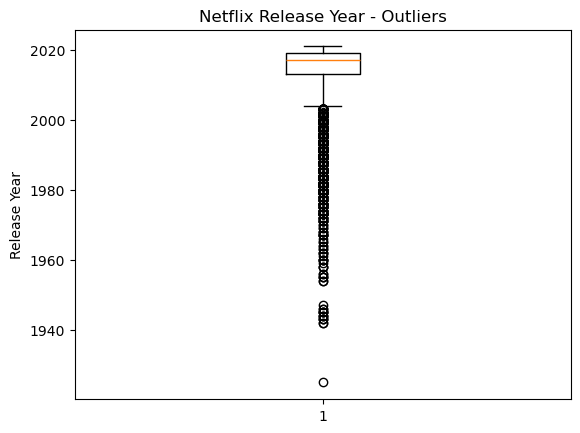

In [19]:
import matplotlib.pyplot as plt

plt.boxplot(data['release_year'])
plt.title("Netflix Release Year - Outliers")
plt.ylabel("Release Year")
plt.show()

In [20]:
data_clean = data[
    (data['release_year'] >= lower_limit) &
    (data['release_year'] <= upper_limit)
]

print("Original Data: ", data.shape)
print("Clean Data: ", data_clean.shape)

Original Data:  (8807, 16)
Clean Data:  (8088, 16)


In [21]:
mean_year = data_clean['release_year'].mean()
median_year = data_clean['release_year'].median()
mode_year = data_clean['release_year'].mode()

print("Mean Release Year: ", mean_year)

print("Median Release Year: ", median_year)


print("Mode Release year: ", mode_year)

Mean Release Year:  2016.3055143422355
Median Release Year:  2017.0
Mode Release year:  0    2018
Name: release_year, dtype: int64


In [22]:
data_clean['release_year'].describe()

count    8088.000000
mean     2016.305514
std         3.786044
min      2004.000000
25%      2015.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

In [23]:
data_clean['type'].value_counts()

type
Movie      5487
TV Show    2601
Name: count, dtype: int64

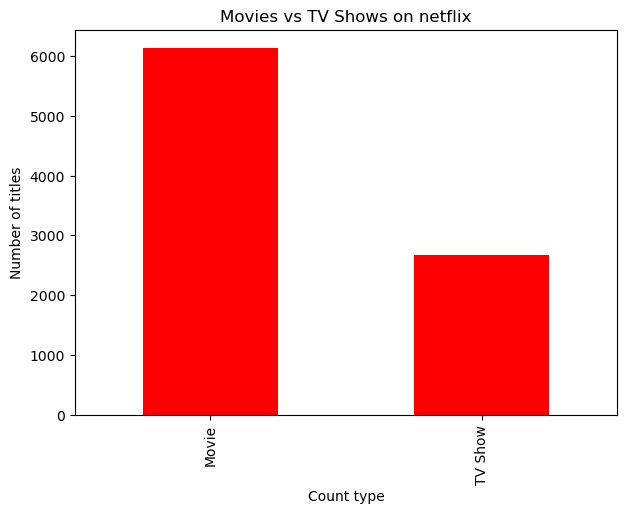

In [24]:
data['type'].value_counts().plot(
    kind = 'bar',
    figsize = (7, 5),
    color = 'red'
)

plt.title("Movies vs TV Shows on netflix")
plt.xlabel("Count type")
plt.ylabel("Number of titles")
plt.show()

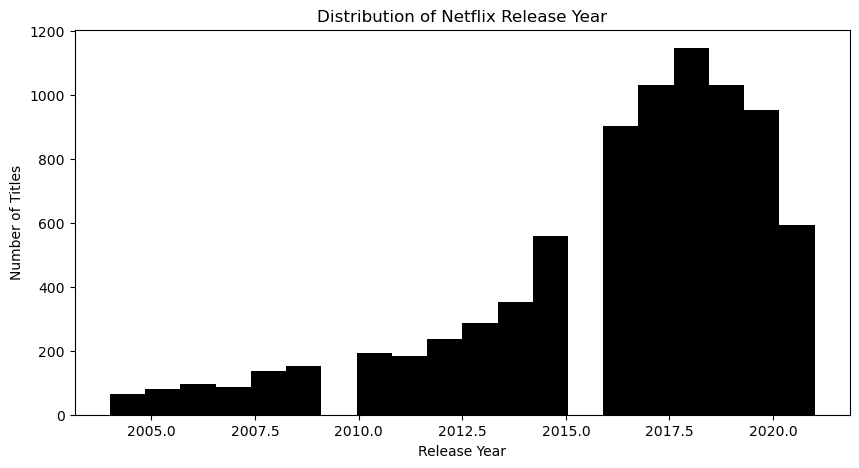

In [41]:
plt.figure(figsize = (10, 5))

plt.hist(
    
    data_clean['release_year'],
    bins = 20,
    color = 'black'
)

plt.title("Distribution of Netflix Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

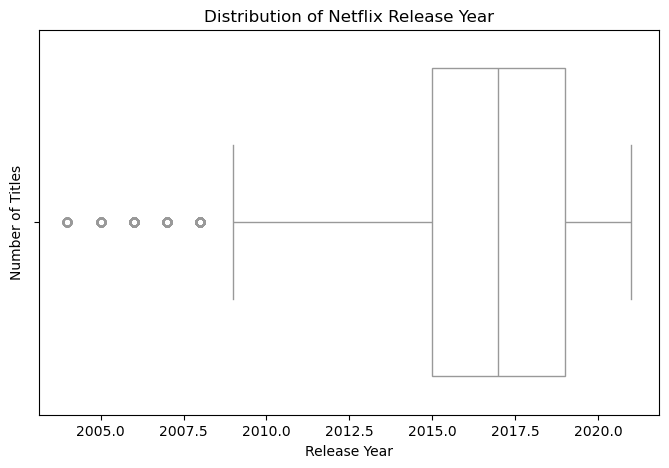

In [39]:
import seaborn as sns

plt.figure(figsize = (8, 5))

sns.boxplot(
    x = data_clean['release_year'],
    color = 'white'
)

plt.title("Distribution of Netflix Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

In [28]:
movies = data_clean[data_clean['type'] == 'Movie'].copy()

In [29]:
movies.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,data_added,year_added,month_added,day_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021-09-25,2021.0,9.0,25.0
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,2021-09-24,2021.0,9.0,24.0
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...,2021-09-24,2021.0,9.0,24.0
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...,2021-09-23,2021.0,9.0,23.0
13,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,"Klara Castanho, Lucca Picon, Júlia Gomes, Marc...",Unknown,"September 22, 2021",2021,TV-PG,91 min,"Children & Family Movies, Comedies",When the clever but socially-awkward Tetê join...,2021-09-22,2021.0,9.0,22.0


In [30]:
movies['duration_minutes'] = (
    movies['duration']
    .str.extract('(\d+)')[0]
    .astype(float)
)

In [32]:
movies[['title', 'duration', 'duration_minutes']].head()

,title,duration,duration_minutes
0,Dick Johnson Is Dead,90 min,90.0
6,My Little Pony: A New Generation,91 min,91.0
9,The Starling,104 min,104.0
12,Je Suis Karl,127 min,127.0
13,Confessions of an Invisible Girl,91 min,91.0


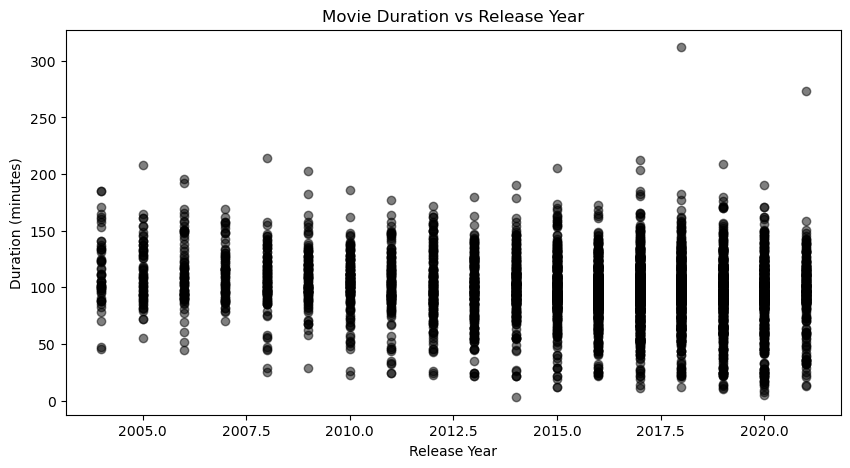

In [40]:
plt.figure(figsize = (10, 5))

plt.scatter(
    movies['release_year'],
    movies['duration_minutes'],
    color = 'black',
    alpha = 0.5
)

plt.title("Movie Duration vs Release Year")
plt.xlabel("Release Year")
plt.ylabel("Duration (minutes)")
plt.show()

# Descriptive Statistics

In [34]:
import statistics

data = [10, 20, 20, 30, 40, 50, 20]

mean = statistics.mean(data)
median = statistics.median(data)
mode = statistics.mode(data)

print("Mean: ", mean)
print("\n Median: ", median)
print("\n Mode: ", mode)


Mean:  27.142857142857142

 Median:  20

 Mode:  20


In [35]:
import numpy as np
from scipy import stats

data = [10, 20, 20, 30, 40, 50, 20]

print("Mean: ", np.mean(data))
print("\nMedian: ", np.median(data))
print("\nMode: ", stats.mode(data, keepdims = False).mode)

Mean:  27.142857142857142

Median:  20.0

Mode:  20


In [36]:
data_range = max(data) - min(data)
variance = statistics.variance(data)
std_deviation = statistics.stdev(data)

print("Mean", round(mean, 2))
print("Median: ", median)
print("Mode: ", mode)
print("Range: ", data_range)
print("Variance: ", round(variance, 2))
print("Standard Deviation: ", round(std_deviation, 2))

Mean 27.14
Median:  20
Mode:  20
Range:  40
Variance:  190.48
Standard Deviation:  13.8


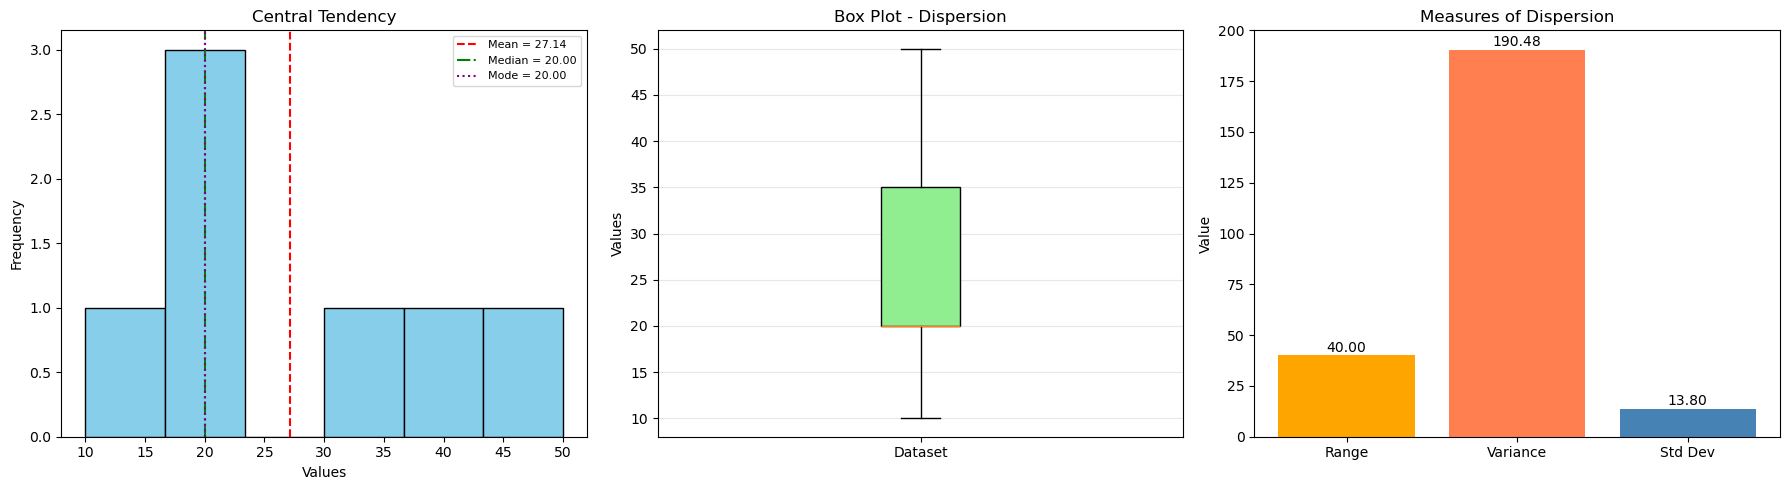

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram - Central Tendency
axes[0].hist(data, bins=6, color="skyblue", edgecolor="black")

axes[0].axvline(mean, color="red", linestyle="--",
                label=f"Mean = {mean:.2f}")

axes[0].axvline(median, color="green", linestyle="-.",
                label=f"Median = {median:.2f}")

axes[0].axvline(mode, color="purple", linestyle=":",
                label=f"Mode = {mode:.2f}")

axes[0].set_title("Central Tendency")
axes[0].set_xlabel("Values")
axes[0].set_ylabel("Frequency")
axes[0].legend(fontsize=8)


# 2. Box Plot - Dispersion
axes[1].boxplot(data, patch_artist=True,
                boxprops=dict(facecolor="lightgreen"))

axes[1].set_title("Box Plot - Dispersion")
axes[1].set_ylabel("Values")
axes[1].set_xticks([1], ["Dataset"])
axes[1].grid(axis="y", alpha=0.3)


# 3. Bar Chart - Measures of Dispersion
names = ["Range", "Variance", "Std Dev"]
values = [data_range, variance, std_deviation]

axes[2].bar(names, values,
            color=["orange", "coral", "steelblue"])

axes[2].set_title("Measures of Dispersion")
axes[2].set_ylabel("Value")

for i, value in enumerate(values):
    axes[2].text(i, value + 0.1,
                 f"{value:.2f}",
                 ha="center", va="bottom")


# Display plots
plt.tight_layout()
plt.show()

In [38]:
print("Mean: ", round(mean, 2))
print("Median: ", median)
print("Mode: ", mode)
print("Range: ", data_range)
print("Variance: ", round(variance, 2))
print("Standard Deviation: ", round(std_deviation, 2))

Mean:  27.14
Median:  20
Mode:  20
Range:  40
Variance:  190.48
Standard Deviation:  13.8
